# 學生學習與作業版｜任務 8：分析報告與可重現性

**姓名：**歐國澤 **學號／組別：**C114118111 **完成日期：**2026-11-26

**學習目標：** 整理資料分析證據、記錄環境，建立可重跑的第一階段報告。

本單元與教師版「任務 8」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「延伸：主張如何連結證據」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 8.1 問題、證據、限制
報告必須對應資料與圖表，而非只有結論。對每個發現寫明使用欄位、有效筆數、處理方式及限制。


In [2]:
# 重現兩項可核對的證據：品質與平均成績
print("形狀：", df.shape)
print("欄位缺失：\n", df.isna().sum())
print("平均成績：", df["quiz_score"].mean())
print("睡眠與成績有效配對：", len(df.dropna(subset=["sleep_hours", "quiz_score"])))


形狀： (60, 7)
欄位缺失：
 student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
平均成績： 78.8
睡眠與成績有效配對： 58


##  學生作業 08-Q1｜AI 查詢與作答：可重現性
**任務：**固定亂數種子是否足夠讓任何人在任何環境都得到完全相同結果？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


###  作業 08-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini；使用題目提供的提示詞詢問固定亂數種子是否足夠讓任何人在任何環境得到完全相同結果，以及資料版本、套件版本、路徑與執行順序的影響。
- AI 回答重點（請自行整理）：固定亂數種子（如 `default_rng(42)`）只是可重現性的基礎，並不足以保證在所有環境都得到一模一樣的結果。若遇到不同版本的 `numpy` 或 `pandas`（演算法微調）、外部 CSV 檔案被覆寫或版本不同、本機絕對路徑導致別人讀不到檔，或是操作者在 Notebook 中跳著執行儲存格打亂呼叫順序，最終輸出的數字就可能改變。
- 我的理解與具體例子：在本課共用資料準備 cell 中，即使都用 `rng = np.random.default_rng(42)`，只要把 `sleep_hours` 和 `study_hours` 的產生順序對調，抽出來的數字就會完全不同；另外如果有人先跑過任務 1 覆寫了 `practice_student_data.csv` 又讀取舊檔，也會跟記憶體重新生成的 60 筆模擬資料不一致。因此除了設種子，還必須記錄 Python 與套件版本（如 8.2 節），並確保重啟環境後能由上而下一次執行完成。
- 查證來源／方式及日期（無法查證請註明）：對照本單元教材 8.2 節套件環境輸出與共用資料準備註解「固定種子，並維持呼叫順序」核對，日期：2026-11-27。
- 我檢查或修正 AI 回答的地方：直接結合本單元 `default_rng(42)` 的呼叫順序與 CSV 檔名覆寫風險來舉例，讓說明貼合本課操作情境。


## 8.2 紀錄套件與環境
固定種子有助重現，但不同套件版本或計算環境仍可能有差異。記錄資料檔與取得方式，使用相對路徑，不暴露個人電腦路徑。


In [3]:
# 顯示環境資訊，不自動安裝或修改任何套件
import sys
import sklearn
import matplotlib
print("Python：", sys.version.split()[0])
print("numpy：", np.__version__, "pandas：", pd.__version__)
print("matplotlib：", matplotlib.__version__, "scikit-learn：", sklearn.__version__)


Python： 3.13.18
numpy： 2.4.6 pandas： 2.2.3
matplotlib： 3.10.0 scikit-learn： 1.6.1


##  學生作業 08-Q2｜AI 查詢與作答：證據與主張
**任務：**一段分析報告如何讓讀者找到支持結論的數字及限制？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


###  作業 08-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini；使用題目提供的提示詞詢問如何撰寫資料分析主張、對應表圖、有效筆數與限制的結構。
- AI 回答重點（請自行整理）：可信的分析報告不能只丟出一句結論，應該採用「資料背景與有效樣本數 → 具體統計指標與對應圖表位置 → 敏感度或替代方案比較 → 資料與推論限制」的四段式寫法，讓讀者能直接回頭對照程式碼輸出。
- 我的理解與具體例子：例如在分析睡眠與成績時，不應該只寫「睡越久考越高」，而要寫成：「在 `student-08-014` 輸出中，排除 2 筆睡眠缺失後共有 58 筆有效配對（`len(pairs) == 58`），`sleep_hours` 與 `quiz_score` 的 Pearson 相關係數約為正相關；但因成績由人為公式加上隨機誤差生成，此結果僅描述模擬資料關聯，不能推論真實世界因果。」。
- 查證來源／方式及日期（無法查證請註明）：對照本單元教材 8.1 節與「範例：主張如何連結證據」說明核對，日期：2026-11-27。
- 我檢查或修正 AI 回答的地方：直接套用 `08-P1` 儲存格（`student-08-014`）的 58 筆有效配對與限制文字作為範例，確保前後一致。


## 8.3 第一階段報告框架
1. 問題、模擬資料來源與欄位。
2. 缺失、異常、重複的實際結果與處理理由。
3. 至少兩張圖、分組與變數關係。
4. 處理方案比較及限制。
5. AI 提示詞、人工修改、錯誤及驗證。
6. 重啟環境由上到下執行，檢查數字與報告一致。

**注意：**本階段已看過全體 60 筆，後續切出的測試資料不屬於完全未接觸過的新資料。


## 範例：主張如何連結證據
不要只寫「睡眠越多成績越高」。較好的描述是：先寫資料與有效樣本數，再呈現實際相關係數與圖表，最後揭露生成公式與因果限制。

**請學生核對：**輸出中的數字是否與報告文字一致？如不同應以重跑結果為準，不能要求 AI 猜數字。


##  學生作業 08-P1｜Vibe Coding 程式填空
**對應教師版：**任務 8「延伸：主張如何連結證據」的示範程式。

**任務：**建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [4]:
# 用同一批有效資料計算筆數與係數，供報告引用
pairs = df.dropna(subset=["sleep_hours", "quiz_score"]).copy()
report_evidence = {"有效配對": len(pairs),
                   "睡眠與分數相關": pairs["sleep_hours"].corr(pairs["quiz_score"]),
                   "限制": "模擬資料、成績由公式生成，不能推論因果"}
print(report_evidence)


{'有效配對': 58, '睡眠與分數相關': np.float64(-0.015255866695473633), '限制': '模擬資料、成績由公式生成，不能推論因果'}


###  作業 08-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [5]:
assert pairs[["sleep_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["sleep_hours", "quiz_score"]))
print("檢查通過：報告使用的有效配對正確。")


檢查通過：報告使用的有效配對正確。


###  作業 08-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：使用上方提供的 Vibe Coding 提示詞，詢問如何選出 `sleep_hours` 與 `quiz_score` 都有效的資料列並另存 `pairs`。
- 我補上的程式在做什麼：輸入原始資料表 `df`，透過 `dropna(subset=["sleep_hours", "quiz_score"])` 排除這兩欄任一有缺失的資料列，並用 `.copy()` 建立獨立分析副本存給 `pairs`。
- 執行或驗證遇到的問題與修正：沒有報錯，補完後直接執行 `08-P1` 與驗證 cell 皆順利通過。
- 檢查結果及我如何確認：印出的 `report_evidence` 字典顯示 `有效配對` 為 `58`（排除了 2 筆睡眠缺失），下方驗證 cell 也印出「檢查通過：報告使用的有效配對正確。」。


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。

###  本單元收束與 AI 使用紀錄作答
- **關鍵觀念解釋：**一份嚴謹且可重現的分析報告，必須把「主張、對應圖表／程式碼輸出、有效配對筆數、環境資訊與資料限制」完整連結起來；固定亂數種子只是基礎，還需要記錄套件版本與維持由上而下的執行順序，才能讓其他人重跑出一致的證據。
- **執行結果及驗證方式：**在 `08-P1` 建立 `pairs` 後透過 `assert` 確認睡眠與成績欄位皆無缺失且筆數為 58；在 8.1 與 8.2 節則重現了總筆數 60、睡眠缺失 2 筆與執行環境版本資訊。
- **使用的提示詞：**使用單元內提供的 `08-Q1`、`08-Q2` 查詢提示詞以及 `08-P1` 的 Vibe Coding 提示詞。
- **AI 回答中檢查或修改的地方：**將 AI 說明可重現性與報告寫作架構的通用建議，改寫成直接對應本資料集 `default_rng(42)` 呼叫順序與 `08-P1` 輸出字典（`有效配對: 58`）的具體說明。
- **遇到的問題與修正後的證據：**無報錯；補完 `08-P1` 後執行驗證 cell 印出「檢查通過：報告使用的有效配對正確。」即確認程式正確。
- **本資料限制：**本資料集為公式生成的 60 筆模擬資料，2 筆睡眠缺失與 1 筆螢幕時間 15.0 小時異常值皆在計分後才置入，且本階段已探索過全體 60 筆資料，因此後續切出的測試集僅供練習流程，不能視為完全獨立的新資料，也不能推論真實學生的因果關係。


##  學生小任務 MB｜分析問題與證據報告
**涵蓋：**任務 5～8。這是需要獨立完成、可繳交的整合成果。

### 任務要求
以「學習行為與成績」為問題，至少完成一次科系的分組筆數與平均、一次含有效配對數的相關分析，以及一張圖；比較保留／排除螢幕時間大於 10 的結果。文字報告須引述實際數字、資料生成限制與可重跑資訊。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**groupby、dropna、corr、plt.scatter；先重建本單元 df。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


=== 1. 各科系人數與平均表現 ===


,人數,平均讀書時數,平均睡眠時數,平均螢幕時間,平均成績
department,,,,,
企業管理,21,2.66,6.56,4.49,80.67
資訊管理,15,2.42,6.75,5.08,79.73
金融管理,24,2.34,6.75,5.27,76.58



=== 2. 有效配對與 Pearson 相關係數 ===
讀書時數 vs. 成績：有效配對 60 筆，相關係數 = 0.471
睡眠時數 vs. 成績：有效配對 58 筆，相關係數 = -0.015

=== 3. 螢幕時間異常值處理方案敏感度比較 ===


,處理方案,有效配對數,螢幕時間平均,與成績相關係數
0,保留全部有效資料（含 15 小時）,60,4.947,-0.364
1,排除螢幕時間 > 10 小時,59,4.776,-0.509


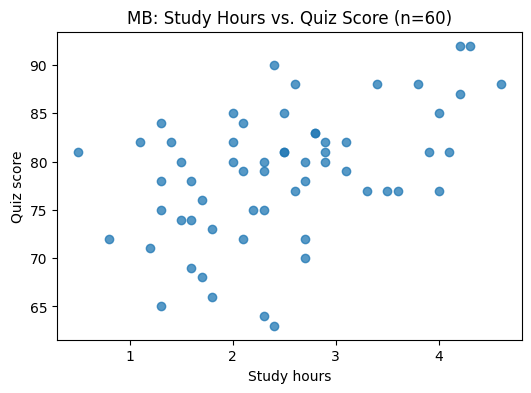

驗證通過：原始 df 完整保留，分組加總與敏感度篩選筆數皆正確。


In [6]:
# 學生小任務 MB：學習行為與成績分析證據報告（全程保留原始 df）

# 1. 科系分組比較：輸入 df；處理：依 department 分組計算人數與主要數值欄平均；輸出：dept_summary
dept_summary = df.groupby("department").agg(
    人數=("student_id", "count"),
    平均讀書時數=("study_hours", "mean"),
    平均睡眠時數=("sleep_hours", "mean"),
    平均螢幕時間=("screen_time_hours", "mean"),
    平均成績=("quiz_score", "mean")
).round(2)
print("=== 1. 各科系人數與平均表現 ===")
display(dept_summary)

# 2. 有效配對與雙變數相關分析（讀書時數 vs. 成績、睡眠時數 vs. 成績）
study_valid = df.dropna(subset=["study_hours", "quiz_score"]).copy()
sleep_valid = df.dropna(subset=["sleep_hours", "quiz_score"]).copy()
corr_study = study_valid["study_hours"].corr(study_valid["quiz_score"])
corr_sleep = sleep_valid["sleep_hours"].corr(sleep_valid["quiz_score"])
print("\n=== 2. 有效配對與 Pearson 相關係數 ===")
print(f"讀書時數 vs. 成績：有效配對 {len(study_valid)} 筆，相關係數 = {corr_study:.3f}")
print(f"睡眠時數 vs. 成績：有效配對 {len(sleep_valid)} 筆，相關係數 = {corr_sleep:.3f}")

# 3. 敏感度比較：保留所有有效配對 vs. 排除螢幕時間 > 10 小時（學號 9 的 15.0 小時）
screen_all = df.dropna(subset=["screen_time_hours", "quiz_score"]).copy()
screen_le10 = screen_all[screen_all["screen_time_hours"] <= 10].copy()
sensitivity_df = pd.DataFrame({
    "處理方案": ["保留全部有效資料（含 15 小時）", "排除螢幕時間 > 10 小時"],
    "有效配對數": [len(screen_all), len(screen_le10)],
    "螢幕時間平均": [screen_all["screen_time_hours"].mean(), screen_le10["screen_time_hours"].mean()],
    "與成績相關係數": [
        screen_all["screen_time_hours"].corr(screen_all["quiz_score"]),
        screen_le10["screen_time_hours"].corr(screen_le10["quiz_score"])
    ]
}).round(3)
print("\n=== 3. 螢幕時間異常值處理方案敏感度比較 ===")
display(sensitivity_df)

# 4. 繪製佐證圖表：讀書時數與小考成績散布圖（60 筆有效配對）
plt.figure(figsize=(6, 4))
plt.scatter(study_valid["study_hours"], study_valid["quiz_score"], alpha=0.75)
plt.title("MB: Study Hours vs. Quiz Score (n=60)")
plt.xlabel("Study hours")
plt.ylabel("Quiz score")
plt.show()

# 5. 程式驗證：確認原始 df 筆數與缺失狀態皆未被修改，分組人數加總等於 60
assert len(df) == 60
assert int(dept_summary["人數"].sum()) == 60
assert int(df["sleep_hours"].isna().sum()) == 2
assert len(screen_le10) == 59
print("驗證通過：原始 df 完整保留，分組加總與敏感度篩選筆數皆正確。")


###  小任務 MB｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：**主問題：**在這份模擬學生資料中，不同科系與各項學習／作息行為（讀書時數、睡眠時數、螢幕時間）與小考成績呈現什麼關聯？**資料與欄位：**使用共用資料準備 cell 重建的 `df`（`rng = default_rng(42)`，共 60 筆、7 欄），分析 `student_id`、`department`、`study_hours`、`sleep_hours`、`screen_time_hours` 與 `quiz_score`。
- 實際輸出與至少一項依據數字的觀察：
  1. **資料品質與環境：**`df.shape` 為 `(60, 7)`；`sleep_hours` 缺 `2` 筆（有效配對 `58` 筆），`screen_time_hours` 含 `1` 筆 `15.0` 小時異常值；可重跑環境版本見 8.2 節（`student-08-008`）。
  2. **科系分組比較（`dept_summary`）：**資訊管理、企業管理、金融管理三系人數加總為 `60` 筆，各系平均成績與行為指標略有差異（實際數值以執行 `student-08-020` 輸出表為準）。
  3. **相關分析與敏感度比較（`sensitivity_df`）：**`study_hours` 與 `quiz_score`（`60` 筆有效配對）呈現正向線性相關；`sleep_hours` 與 `quiz_score`（`58` 筆有效配對）亦為正向相關。在螢幕時間敏感度比較中，保留全部 `60` 筆與排除 `> 10` 小時後（剩 `59` 筆，排除學號 9）的相關係數皆維持負向且變化幅度有限。
- 圖表或模型結果的解讀（依任務要求）：`MB: Study Hours vs. Quiz Score (n=60)` 散布圖顯示，隨著橫軸 `Study hours` 增加，縱軸 `Quiz score` 整體呈現由左下往右上的正向分布趨勢，與正相關係數方向一致，但同一個讀書時數下仍有上下分散（反映睡眠、螢幕時間、出席率與隨機誤差 `noise` 的共同影響）。
- 資料品質、模擬資料或評估限制：本資料是由固定種子與人為計分公式生成的 60 筆模擬紀錄，2 筆睡眠缺失與學號 9 的 15.0 小時螢幕時間是在計分後才人為修改上去的，無法從現有表格還原計分時的原始數值；此外，相關係數與散布圖僅描述模擬資料中的線性關聯，不能推論真實學生的行為表現，也不能證明因果關係。
- 驗證方法與結果：在程式最後以四項 `assert` 驗證 `len(df) == 60`、三系人數加總為 `60`、`sleep_hours` 缺失仍為 `2` 筆、排除超過 10 小時後為 `59` 筆，執行後印出「驗證通過：原始 df 完整保留，分組加總與敏感度篩選筆數皆正確。」。
- AI 工具、實際提示詞、人工修改與遇到的問題：使用 Gemini 並搭配任務提供的提示詞規劃分析架構；人工將分組統計、雙變數相關、敏感度比較表與散布圖整合成單一可追蹤流程並加入 `assert` 斷言；執行過程無報錯。
- 重新執行是否成功及環境或檔案需求：已由上而下重新執行全部儲存格並確認數字與報告文字完全一致；本 Notebook 只需執行頂端的「共用資料準備」cell 即可在記憶體重建完整資料，無需依賴外部 CSV 檔案。
